# Figure S1

In [2]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_model_comparison,
    load_convergence,
    DATASET_LABELS,
)
import numpy as np
import matplotlib.pyplot as plt

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]

### Helper functions

In [11]:
def is_nonconverged(convergence, dataset, model):
    row = convergence[(convergence["dataset"] == dataset) & (convergence["model"] == model)]
    if row.empty:
        return False
    return bool(row["converged"].values[0] == False or row["singular"].values[0] == True)


def bar_color(v, threshold, pos_color, neutral_color, neg_color):
    if v > threshold:
        return pos_color
    if v < -threshold:
        return neg_color
    return neutral_color


def plot_confound_comparison(ax, model_comparison, convergence, dataset, models, labels,
                             threshold, pos_color, neutral_color, neg_color, ylim,
                             show_ylabel=True):
    """Ln Bayes Factor of the choice-history model (M2) vs each confound
    model, sorted best-for-confound to best-for-choice-history. Background
    shaded by direction (light tint above +threshold in pos_color, below
    -threshold in neg_color), labeled "Confound model favored" /
    "Previous choice model favored". ylim is fixed (not auto-scaled) so all
    panels share the same scale. Hatched bars mark non-converged/singular
    fits."""
    ds_mc = model_comparison[
        (model_comparison["dataset"] == dataset) & (model_comparison["model"].isin(models))
    ].copy()
    ds_mc = (
        ds_mc.set_index("model")
        .reindex(models)
        .dropna(subset=["BF_vs_reference"])
        .sort_values("BF_vs_reference", ascending=False)
    )

    bf_values = ds_mc["BF_vs_reference"].values
    x_pos = np.arange(len(ds_mc))
    bar_labels = [labels[m] for m in ds_mc.index]
    colors = [bar_color(v, threshold, pos_color, neutral_color, neg_color) for v in bf_values]
    hatches = ["///" if is_nonconverged(convergence, dataset, m) else "" for m in ds_mc.index]

    for i, (val, color, hatch) in enumerate(zip(bf_values, colors, hatches)):
        ax.bar(x_pos[i], val, color=color, hatch=hatch, edgecolor="black", linewidth=0.5, zorder=2)

    ax.set_ylim(*ylim)
    ax.axhspan(threshold, ylim[1], facecolor=pos_color, alpha=0.08, zorder=0)
    ax.axhspan(ylim[0], -threshold, facecolor=neg_color, alpha=0.08, zorder=0)

    ax.axhline(0, color="black", linestyle="-", linewidth=1.5, zorder=1)
    ax.axhline(threshold, color="black", linestyle="--", linewidth=0.8, alpha=0.25, zorder=1)
    ax.axhline(-threshold, color="black", linestyle="--", linewidth=0.8, alpha=0.25, zorder=1)

    ax.text(0.5, 0.97, "Confound model favored", transform=ax.transAxes,
           ha="center", va="top", fontsize=9, color=pos_color, fontweight="bold")
    ax.text(0.5, 0.03, "Previous choice model favored", transform=ax.transAxes,
           ha="center", va="bottom", fontsize=9, color=neg_color, fontweight="bold")

    ax.set_xticks(x_pos)
    ax.set_xticklabels(bar_labels, rotation=45, ha="right")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if show_ylabel:
        ax.set_ylabel("Ln(Bayes Factor):\nPrev. Choice Model vs\nConfound Model")

### 1x3 figure: model comparison against confound models
Columns = datasets. Ln Bayes Factor of the choice-history model (M2) vs each confound model (previous EV, delta EV, previous gain, previous loss, with and without choice history). Positive = evidence for the confound model; negative = evidence for the choice-history model. Hatched bars mark non-converged/singular fits.

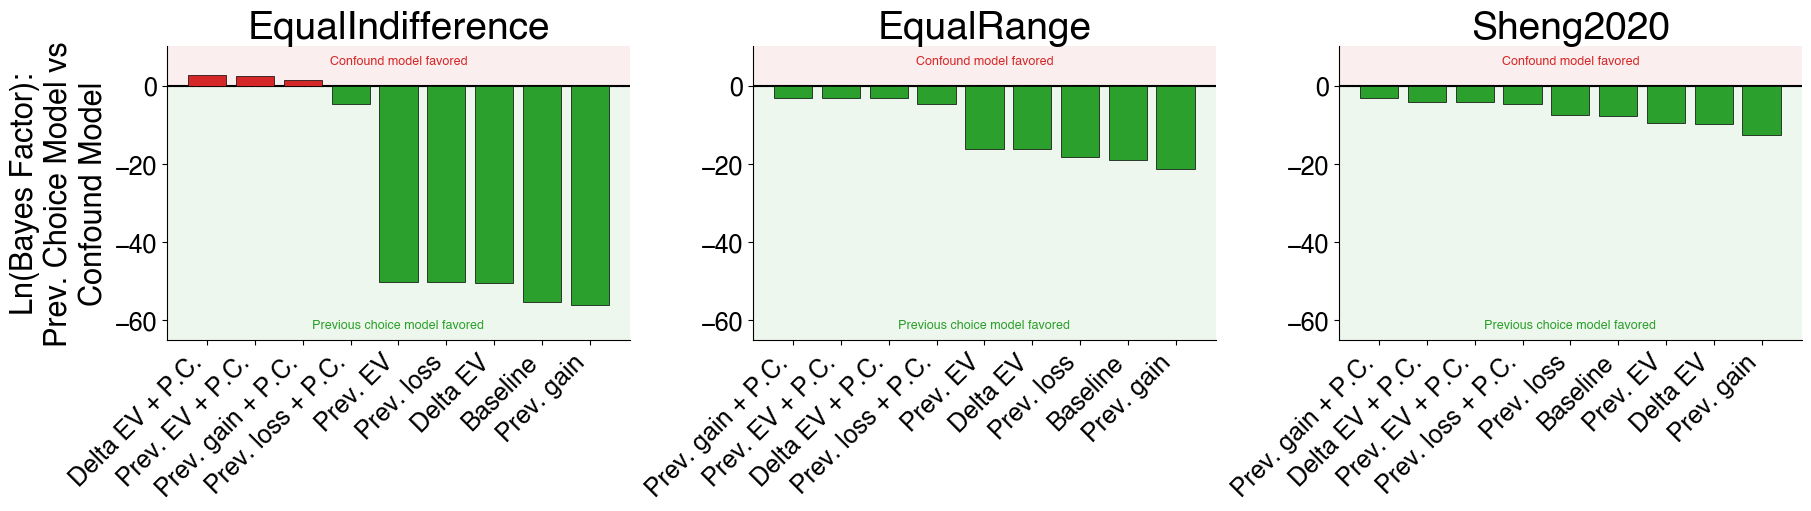

In [15]:
MODEL_LABELS = {
    "M1_part1":  "Baseline",
    "M3_part1":  "Prev. EV",
    "M4_part1":  "Delta EV",
    "M5_part1":  "Prev. gain",
    "M6_part1":  "Prev. loss",
    "M7_part1":  "Prev. EV + P.C.",
    "M8_part1":  "Delta EV + P.C.",
    "M9_part1":  "Prev. gain + P.C.",
    "M10_part1": "Prev. loss + P.C.",
}

BF_THRESHOLD = 0
POS_BAR_COLOR = "#D62728"
NEUTRAL_BAR_COLOR = "#EDADAD"
NEG_BAR_COLOR = "#2CA02C"
# Hand-coded (not auto-scaled) so all 3 panels share the same y-axis; the
# most extreme bar across datasets is ~-56 (equalIndifference), so -65/10
# leaves headroom for that plus the "favored" labels top and bottom.
BF_YLIM = (-65, 10)

model_comparison = load_model_comparison("behavior")
convergence = load_convergence()
models = list(MODEL_LABELS.keys())

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 5), layout="constrained")

for col, ds in enumerate(DATASETS):
    ax = axes[col]
    plot_confound_comparison(ax, model_comparison, convergence, ds, models, MODEL_LABELS,
                             BF_THRESHOLD, POS_BAR_COLOR, NEUTRAL_BAR_COLOR, NEG_BAR_COLOR,
                             BF_YLIM, show_ylabel=(col == 0))
    ax.set_title(DATASET_LABELS.get(ds, ds))

fig.savefig("saved/figureS1.svg", dpi=300, bbox_inches="tight")
plt.show()